In [2]:
import pandas as pd

# Load the dataset
df = pd.read_csv(r'/Users/adityavardhan/Downloads/day.csv')

# Display basic information and first few rows
df.info(), df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     730 non-null    int64  
 1   dteday      730 non-null    object 
 2   season      730 non-null    int64  
 3   yr          730 non-null    int64  
 4   mnth        730 non-null    int64  
 5   holiday     730 non-null    int64  
 6   weekday     730 non-null    int64  
 7   workingday  730 non-null    int64  
 8   weathersit  730 non-null    int64  
 9   temp        730 non-null    float64
 10  atemp       730 non-null    float64
 11  hum         730 non-null    float64
 12  windspeed   730 non-null    float64
 13  casual      730 non-null    int64  
 14  registered  730 non-null    int64  
 15  cnt         730 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.4+ KB


(None,
    instant      dteday  season  yr  mnth  holiday  weekday  workingday  \
 0        1  01-01-2018       1   0     1        0        1           1   
 1        2  02-01-2018       1   0     1        0        2           1   
 2        3  03-01-2018       1   0     1        0        3           1   
 3        4  04-01-2018       1   0     1        0        4           1   
 4        5  05-01-2018       1   0     1        0        5           1   
 
    weathersit       temp     atemp      hum  windspeed  casual  registered  \
 0           2  14.110847  18.18125  80.5833  10.749882     331         654   
 1           2  14.902598  17.68695  69.6087  16.652113     131         670   
 2           1   8.050924   9.47025  43.7273  16.636703     120        1229   
 3           1   8.200000  10.60610  59.0435  10.739832     108        1454   
 4           1   9.305237  11.46350  43.6957  12.522300      82        1518   
 
     cnt  
 0   985  
 1   801  
 2  1349  
 3  1562  
 4  1600  

In [4]:
# Convert dteday to datetime format
df['dteday'] = pd.to_datetime(df['dteday'], format='%d-%m-%Y')

# Convert categorical variables
df['season'] = df['season'].map({1: 'spring', 2: 'summer', 3: 'fall', 4: 'winter'})
df['weathersit'] = df['weathersit'].map({
    1: 'clear', 
    2: 'mist', 
    3: 'light_snow_rain', 
    4: 'heavy_rain_snow'
})

# Check unique values to confirm mapping
df[['season', 'weathersit']].nunique()

season        4
weathersit    3
dtype: int64

In [2]:
# Convert dteday to datetime format
df['dteday'] = pd.to_datetime(df['dteday'], format='%d-%m-%Y')

# Convert categorical variables from numeric to descriptive text values
df['season'] = df['season'].map({1: 'spring', 2: 'summer', 3: 'fall', 4: 'winter'})
df['weathersit'] = df['weathersit'].map({
    1: 'clear',              # Clear, few clouds
    2: 'mist',               # Mist, cloudy conditions
    3: 'light_snow_rain',    # Light snow or rain
    4: 'heavy_rain_snow'     # Heavy rain, snow, or thunderstorms
})

# Check unique values to confirm mapping was successful
df[['season', 'weathersit']].nunique()

NameError: name 'pd' is not defined

In [8]:
df.dtypes

instant                int64
dteday        datetime64[ns]
season                object
yr                     int64
mnth                   int64
holiday                int64
weekday                int64
workingday             int64
weathersit            object
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object

In [12]:
# Identify non-numeric columns
non_numeric_cols = df_numeric.select_dtypes(exclude=["number"]).columns
non_numeric_cols


Index(['season', 'weathersit'], dtype='object')

In [14]:
# Check unique values in each column to identify potential non-numeric entries
df_numeric.applymap(lambda x: type(x)).nunique()


/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_6609/2916129041.py:2: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_numeric.applymap(lambda x: type(x)).nunique()


season        1
yr            1
mnth          1
holiday       1
weekday       1
workingday    1
weathersit    1
temp          1
atemp         1
hum           1
windspeed     1
cnt           1
dtype: int64

In [16]:
# Check for categorical columns in the original dataframe
categorical_cols = df.select_dtypes(include=["object"]).columns
categorical_cols


Index(['season', 'weathersit'], dtype='object')

In [18]:
# Check unique values in each column to find categorical variables
unique_values = {col: df[col].unique() for col in df.columns}
unique_values


{'instant': array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
         14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
         27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
         40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
         53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
         66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
         79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
         92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
        105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
        118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
        131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
        144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
        157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
        170, 171, 172, 173, 174, 175, 17

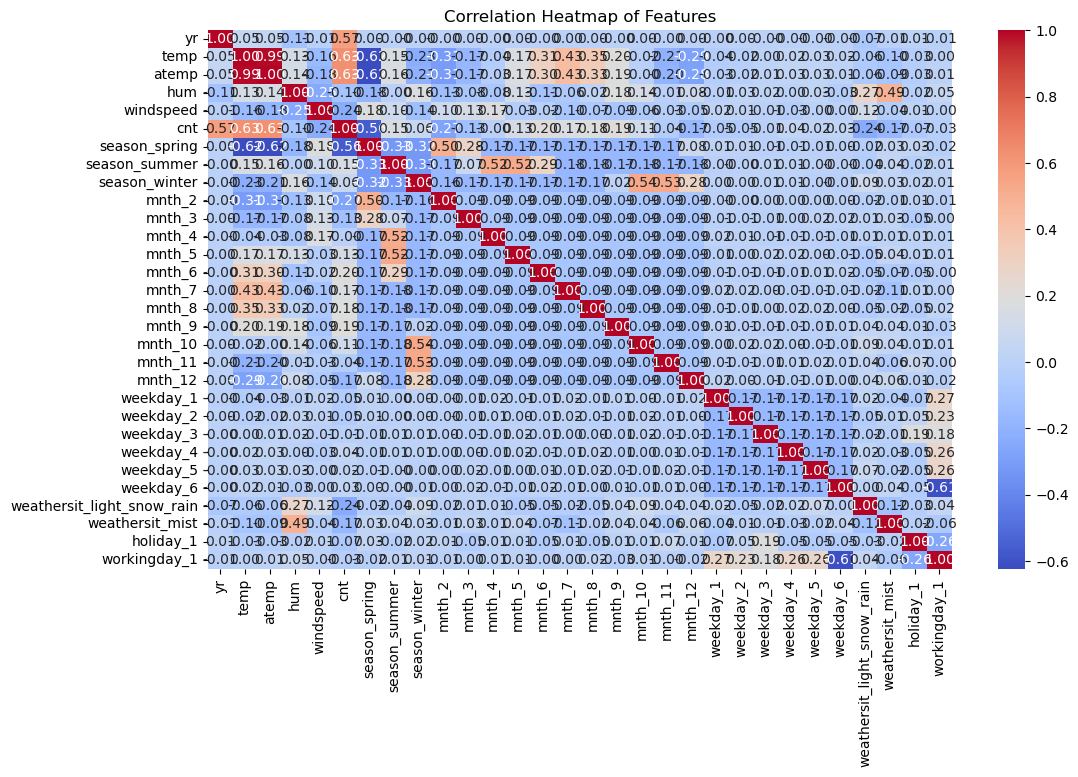

In [20]:
# Convert categorical columns to categorical type
categorical_cols = ["season", "mnth", "weekday", "weathersit", "holiday", "workingday"]
df[categorical_cols] = df[categorical_cols].astype("category")

# One-hot encode categorical variables
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Drop non-relevant columns again
df_encoded = df_encoded.drop(columns=["instant", "dteday", "casual", "registered"])

# Compute correlation matrix
corr_matrix = df_encoded.corr()

# Plot heatmap
plt.figure(figsize=(12, 7))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Features")
plt.show()


In [22]:
# Display current column names in df
df.columns


Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')

In [24]:
# Update categorical column list based on available columns
categorical_cols = ["mnth", "holiday", "weekday", "workingday"]

# Convert categorical columns to category type
df[categorical_cols] = df[categorical_cols].astype("category")

# One-hot encode categorical variables
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Drop non-relevant columns again
df_encoded = df_encoded.drop(columns=["instant", "dteday", "casual", "registered"])

# Compute correlation matrix
corr_matrix = df_encoded.corr()

# Plot heatmap
plt.figure(figsize=(12, 7))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Features")
plt.show()


ValueError: could not convert string to float: 'spring'

In [26]:
print(df_encoded.dtypes)


season          category
yr                 int64
weathersit      category
temp             float64
atemp            float64
hum              float64
windspeed        float64
cnt                int64
mnth_2              bool
mnth_3              bool
mnth_4              bool
mnth_5              bool
mnth_6              bool
mnth_7              bool
mnth_8              bool
mnth_9              bool
mnth_10             bool
mnth_11             bool
mnth_12             bool
holiday_1           bool
weekday_1           bool
weekday_2           bool
weekday_3           bool
weekday_4           bool
weekday_5           bool
weekday_6           bool
workingday_1        bool
dtype: object


In [28]:
df_encoded = pd.get_dummies(df_encoded, drop_first=True)


In [30]:
print(df_encoded.dtypes)


yr                              int64
temp                          float64
atemp                         float64
hum                           float64
windspeed                     float64
cnt                             int64
mnth_2                           bool
mnth_3                           bool
mnth_4                           bool
mnth_5                           bool
mnth_6                           bool
mnth_7                           bool
mnth_8                           bool
mnth_9                           bool
mnth_10                          bool
mnth_11                          bool
mnth_12                          bool
holiday_1                        bool
weekday_1                        bool
weekday_2                        bool
weekday_3                        bool
weekday_4                        bool
weekday_5                        bool
weekday_6                        bool
workingday_1                     bool
season_spring                    bool
season_summe

In [32]:
corr_matrix = df_encoded.corr()


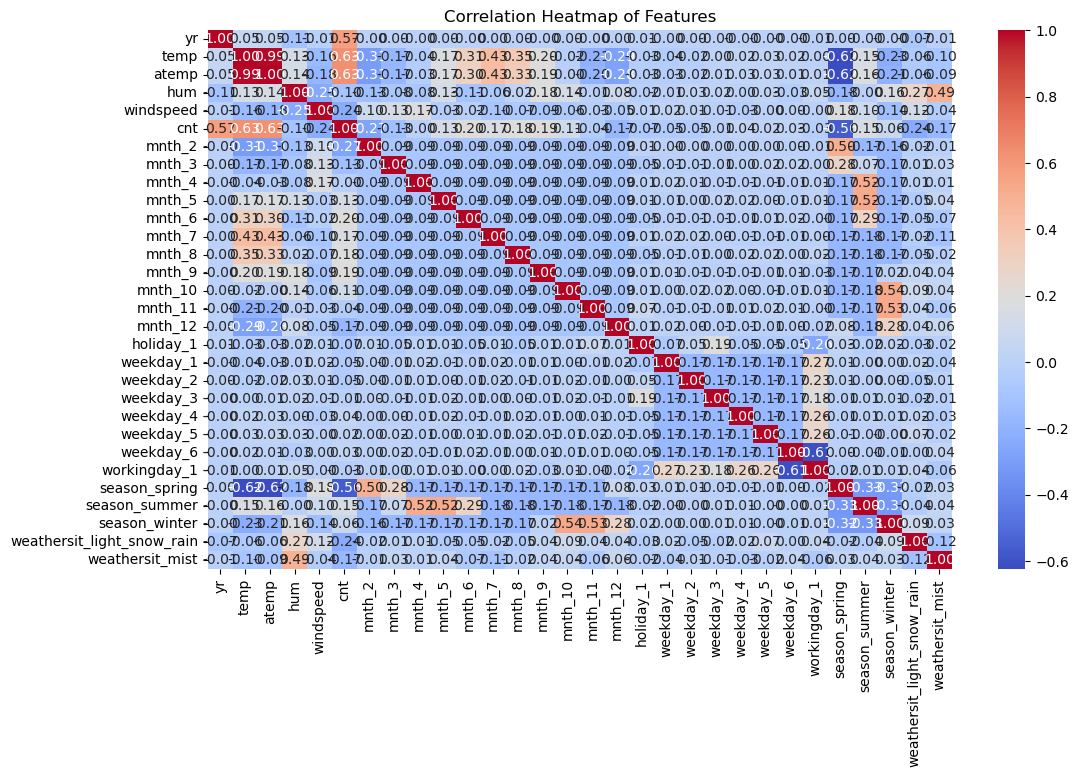

In [34]:
corr_matrix = df_encoded.corr()
plt.figure(figsize=(12, 7))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Features")
plt.show()


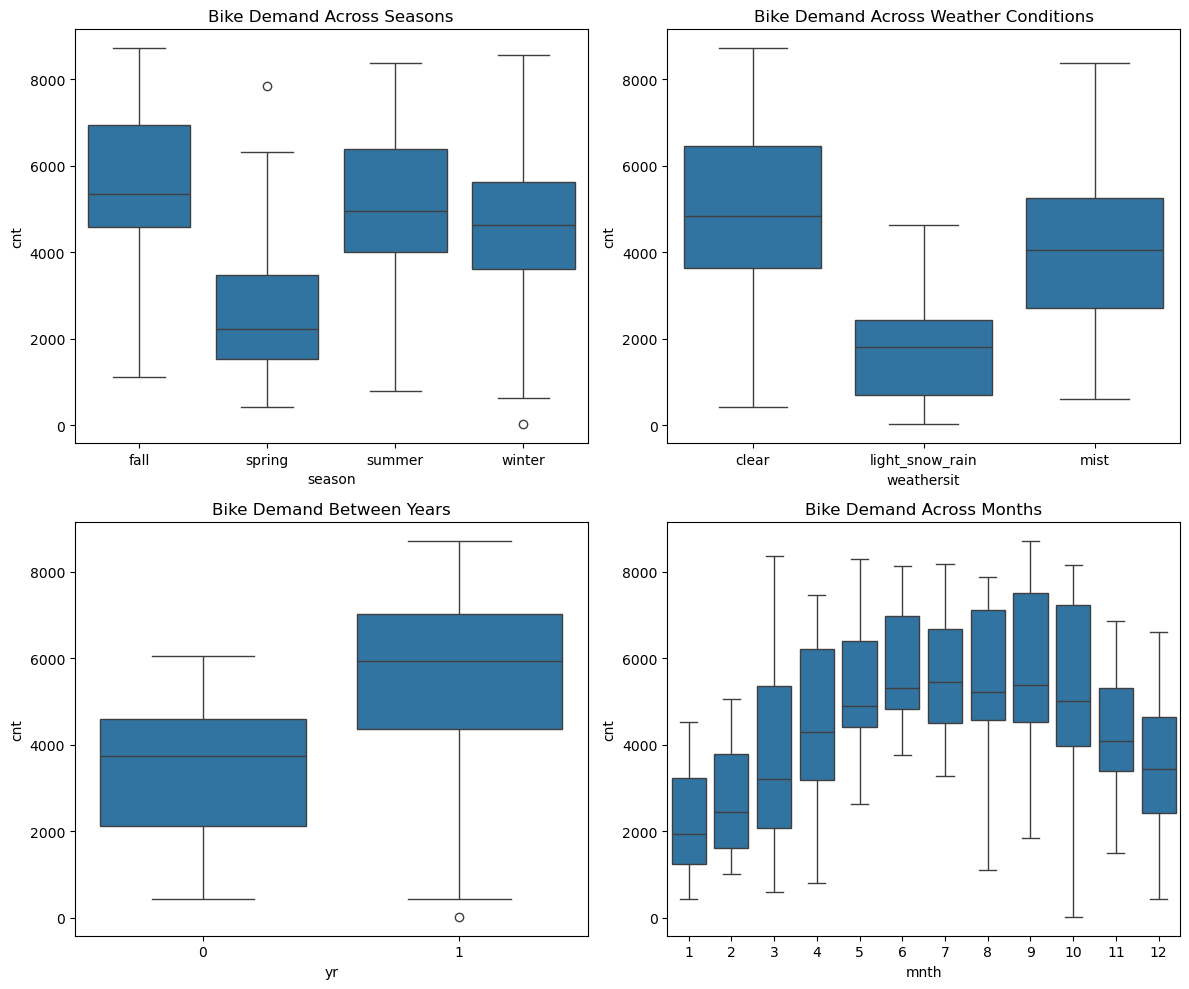

In [38]:
# Visualizing categorical variables against 'cnt'

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Season vs Count
sns.boxplot(x="season", y="cnt", data=df, ax=axes[0, 0])
axes[0, 0].set_title("Bike Demand Across Seasons")

# Weather Situation vs Count
sns.boxplot(x="weathersit", y="cnt", data=df, ax=axes[0, 1])
axes[0, 1].set_title("Bike Demand Across Weather Conditions")

# Year vs Count
sns.boxplot(x="yr", y="cnt", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Bike Demand Between Years")

# Month vs Count
sns.boxplot(x="mnth", y="cnt", data=df, ax=axes[1, 1])
axes[1, 1].set_title("Bike Demand Across Months")

plt.tight_layout()
plt.show()




In [40]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Convert categorical numerical variables into actual categorical values
df['season'] = df['season'].map({1: 'Winter', 2: 'Spring', 3: 'Summer', 4: 'Fall'})
df['weathersit'] = df['weathersit'].map({1: 'Clear', 2: 'Mist/Cloudy', 3: 'Light Rain/Snow', 4: 'Heavy Rain/Snow'})

# One-hot encoding categorical variables
df = pd.get_dummies(df, columns=['season', 'weathersit'], drop_first=True)

# Selecting features and target variable
X = df.drop(columns=['cnt', 'instant', 'dteday', 'casual', 'registered'])  # Dropping non-useful and target-related columns
y = df['cnt']

# Splitting into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled[:5], X_test_scaled[:5]  # Display first few scaled values


(array([[-1.02426696,  0.70319848,  5.45314974, -0.01031433, -1.498147  ,
          0.9418131 ,  0.89618942,  1.09448449,  0.35214862],
        [-1.02426696,  1.57882303, -0.18338026, -1.51620715, -1.498147  ,
         -1.02924785, -0.92289684, -0.06306076, -1.14413107],
        [ 0.97630797,  1.57882303, -0.18338026, -0.01031433,  0.66749124,
         -0.14204378, -0.0720015 ,  0.69593653, -0.16335958],
        [ 0.97630797, -1.04805061, -0.18338026, -1.51620715, -1.498147  ,
          0.06832873,  0.15053303,  0.85124976, -1.01113378],
        [-1.02426696, -0.46430092, -0.18338026,  0.49164994,  0.66749124,
          0.32900316,  0.35755469,  1.42855948,  1.21640379]]),
 array([[ 0.97630797, -0.75617576, -0.18338026, -1.51620715, -1.498147  ,
         -0.03685752,  0.04511477, -0.92754839,  0.06103826],
        [-1.02426696, -0.46430092, -0.18338026, -0.51227861,  0.66749124,
          0.90980227,  0.83376697,  1.29375495,  0.36874989],
        [-1.02426696,  0.99507333, -0.18338026

In [42]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Train the linear regression model
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Predict on the test set
y_pred = model.predict(X_test_scaled)

# Evaluate the model
r2 = r2_score(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)

r2, rmse



/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(0.7722647419697043, 882.8939906930896)

In [44]:
from sklearn.feature_selection import RFE

# Perform Recursive Feature Elimination
rfe = RFE(estimator=LinearRegression(), n_features_to_select=10)
rfe.fit(X_train_scaled, y_train)

# Get selected features
selected_features = X_train.columns[rfe.support_]
selected_features


/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_selection/_rfe.py:291: UserWarning: Found n_features_to_select=10 > n_features=9. There will be no feature selection and all features will be kept.
  warnings.warn(


Index(['yr', 'mnth', 'holiday', 'weekday', 'workingday', 'temp', 'atemp',
       'hum', 'windspeed'],
      dtype='object')

In [46]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression

# Perform Recursive Feature Elimination
rfe = RFE(estimator=LinearRegression(), n_features_to_select=10)
rfe.fit(X_train_scaled, y_train)

# Get selected features
selected_features = X_train.columns[rfe.support_]
print("Selected Features:", selected_features)


Selected Features: Index(['yr', 'mnth', 'holiday', 'weekday', 'workingday', 'temp', 'atemp',
       'hum', 'windspeed'],
      dtype='object')


/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_selection/_rfe.py:291: UserWarning: Found n_features_to_select=10 > n_features=9. There will be no feature selection and all features will be kept.
  warnings.warn(


In [48]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression

# Perform Recursive Feature Elimination
rfe = RFE(estimator=LinearRegression(), n_features_to_select=10)
rfe.fit(X_train_scaled, y_train)

# Get selected features
selected_features = X_train.columns[rfe.support_]
print("Selected Features:", selected_features)


Selected Features: Index(['yr', 'mnth', 'holiday', 'weekday', 'workingday', 'temp', 'atemp',
       'hum', 'windspeed'],
      dtype='object')


/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_selection/_rfe.py:291: UserWarning: Found n_features_to_select=10 > n_features=9. There will be no feature selection and all features will be kept.
  warnings.warn(


In [54]:
import pandas as pd

# Convert scaled arrays back to DataFrame with original column names
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_train.columns)

# Select features using column names
X_train_selected = X_train_scaled_df[selected_features]
X_test_selected = X_test_scaled_df[selected_features]



In [56]:
# Train a new linear regression model with selected features
model_selected = LinearRegression()
model_selected.fit(X_train_selected, y_train)

# Make predictions on the test set
y_pred_selected = model_selected.predict(X_test_selected)

# Evaluate the model
r2_selected = r2_score(y_test, y_pred_selected)
rmse_selected = mean_squared_error(y_test, y_pred_selected, squared=False)

r2_selected, rmse_selected


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(0.7722647419697043, 882.8939906930896)

In [58]:
# Train a new linear regression model with selected features
model_selected = LinearRegression()
model_selected.fit(X_train_selected, y_train)

# Make predictions on the test set
y_pred_selected = model_selected.predict(X_test_selected)

# Evaluate the model
r2_selected = r2_score(y_test, y_pred_selected)
rmse_selected = mean_squared_error(y_test, y_pred_selected, squared=False)

print(f"R² Score: {r2_selected}")
print(f"RMSE: {rmse_selected}")


R² Score: 0.7722647419697043
RMSE: 882.8939906930896


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [60]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, interaction_only=True)
X_train_poly = poly.fit_transform(X_train_selected)
X_test_poly = poly.transform(X_test_selected)

# Train a model on polynomial features
model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train)
y_pred_poly = model_poly.predict(X_test_poly)

# Evaluate
r2_poly = r2_score(y_test, y_pred_poly)
rmse_poly = mean_squared_error(y_test, y_pred_poly, squared=False)

print("R² Score (Polynomial Features):", r2_poly)
print("RMSE (Polynomial Features):", rmse_poly)


R² Score (Polynomial Features): 0.7712318501279001
RMSE (Polynomial Features): 884.8939057009061


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [62]:
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=1.0)
ridge.fit(X_train_selected, y_train)
y_pred_ridge = ridge.predict(X_test_selected)

# Evaluate Ridge Model
r2_ridge = r2_score(y_test, y_pred_ridge)
rmse_ridge = mean_squared_error(y_test, y_pred_ridge, squared=False)

print("R² Score (Ridge Regression):", r2_ridge)
print("RMSE (Ridge Regression):", rmse_ridge)


R² Score (Ridge Regression): 0.7942057302230074
RMSE (Ridge Regression): 839.2861629903082


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [64]:
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=0.1)
lasso.fit(X_train_selected, y_train)
y_pred_lasso = lasso.predict(X_test_selected)

# Evaluate Lasso Model
r2_lasso = r2_score(y_test, y_pred_lasso)
rmse_lasso = mean_squared_error(y_test, y_pred_lasso, squared=False)

print("R² Score (Lasso Regression):", r2_lasso)
print("RMSE (Lasso Regression):", rmse_lasso)


R² Score (Lasso Regression): 0.7741565864230409
RMSE (Lasso Regression): 879.2191502748182


/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.122e+07, tolerance: 2.228e+05
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [66]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train_selected, y_train)
y_pred_rf = rf.predict(X_test_selected)

# Evaluate Random Forest Model
r2_rf = r2_score(y_test, y_pred_rf)
rmse_rf = mean_squared_error(y_test, y_pred_rf, squared=False)

print("R² Score (Random Forest):", r2_rf)
print("RMSE (Random Forest):", rmse_rf)


R² Score (Random Forest): 0.9054202622253184
RMSE (Random Forest): 568.9740730358337


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [68]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge, Lasso

# Define parameter grid
param_grid = {'alpha': [0.01, 0.1, 1, 10, 100]}

# Ridge Regression Tuning
ridge = Ridge()
ridge_grid = GridSearchCV(ridge, param_grid, scoring='r2', cv=5)
ridge_grid.fit(X_train_selected, y_train)

print("Best Ridge Alpha:", ridge_grid.best_params_)
print("Best Ridge R² Score:", ridge_grid.best_score_)

# Lasso Regression Tuning
lasso = Lasso()
lasso_grid = GridSearchCV(lasso, param_grid, scoring='r2', cv=5)
lasso_grid.fit(X_train_selected, y_train)

print("Best Lasso Alpha:", lasso_grid.best_params_)
print("Best Lasso R² Score:", lasso_grid.best_score_)


Best Ridge Alpha: {'alpha': 0.1}
Best Ridge R² Score: 0.7283679368153045
Best Lasso Alpha: {'alpha': 0.1}
Best Lasso R² Score: 0.7283342025282391


/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.108e+08, tolerance: 1.715e+05
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.126e+08, tolerance: 1.813e+05
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.539e+07, toler

In [70]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

# Define parameter grid for Random Forest
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Random Forest Model
rf = RandomForestRegressor(random_state=42)

# Randomized Search CV
rf_random = RandomizedSearchCV(rf, param_grid_rf, n_iter=10, scoring='r2', cv=5, random_state=42, n_jobs=-1)
rf_random.fit(X_train_selected, y_train)

print("Best Random Forest Parameters:", rf_random.best_params_)
print("Best Random Forest R² Score:", rf_random.best_score_)


Best Random Forest Parameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 30}
Best Random Forest R² Score: 0.8382511093944339


In [72]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge, Lasso

# Define parameter grid
param_grid = {'alpha': [0.01, 0.1, 1, 10, 100]}

# Ridge Regression Tuning
ridge = Ridge()
ridge_grid = GridSearchCV(ridge, param_grid, scoring='r2', cv=5)
ridge_grid.fit(X_train_selected, y_train)

print("Best Ridge Alpha:", ridge_grid.best_params_)
print("Best Ridge R² Score:", ridge_grid.best_score_)

# Lasso Regression Tuning
lasso = Lasso()
lasso_grid = GridSearchCV(lasso, param_grid, scoring='r2', cv=5)
lasso_grid.fit(X_train_selected, y_train)

print("Best Lasso Alpha:", lasso_grid.best_params_)
print("Best Lasso R² Score:", lasso_grid.best_score_)


Best Ridge Alpha: {'alpha': 0.1}
Best Ridge R² Score: 0.7283679368153045
Best Lasso Alpha: {'alpha': 0.1}
Best Lasso R² Score: 0.7283342025282391


/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.108e+08, tolerance: 1.715e+05
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.126e+08, tolerance: 1.813e+05
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.539e+07, toler

In [74]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

# Define parameter grid for Random Forest
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Random Forest Model
rf = RandomForestRegressor(random_state=42)

# Randomized Search CV
rf_random = RandomizedSearchCV(rf, param_grid_rf, n_iter=10, scoring='r2', cv=5, random_state=42, n_jobs=-1)
rf_random.fit(X_train_selected, y_train)

print("Best Random Forest Parameters:", rf_random.best_params_)
print("Best Random Forest R² Score:", rf_random.best_score_)


Best Random Forest Parameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 30}
Best Random Forest R² Score: 0.8382511093944339


In [76]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd

# Train the best Ridge Regression model
best_ridge = Ridge(alpha=ridge_grid.best_params_['alpha'])
best_ridge.fit(X_train_selected, y_train)
y_pred_ridge = best_ridge.predict(X_test_selected)

# Train the best Lasso Regression model
best_lasso = Lasso(alpha=lasso_grid.best_params_['alpha'])
best_lasso.fit(X_train_selected, y_train)
y_pred_lasso = best_lasso.predict(X_test_selected)

# Train the best Random Forest model
best_rf = RandomForestRegressor(**rf_random.best_params_, random_state=42)
best_rf.fit(X_train_selected, y_train)
y_pred_rf = best_rf.predict(X_test_selected)

# Evaluate models
r2_ridge = r2_score(y_test, y_pred_ridge)
rmse_ridge = mean_squared_error(y_test, y_pred_ridge, squared=False)

r2_lasso = r2_score(y_test, y_pred_lasso)
rmse_lasso = mean_squared_error(y_test, y_pred_lasso, squared=False)

r2_rf = r2_score(y_test, y_pred_rf)
rmse_rf = mean_squared_error(y_test, y_pred_rf, squared=False)

# Compare results
model_performance = {
    "Model": ["Ridge Regression", "Lasso Regression", "Random Forest"],
    "R² Score": [r2_ridge, r2_lasso, r2_rf],
    "RMSE": [rmse_ridge, rmse_lasso, rmse_rf]
}

performance_df = pd.DataFrame(model_performance)
print(performance_df)


/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.122e+07, tolerance: 2.228e+05
  model = cd_fast.enet_coordinate_descent(


              Model  R² Score        RMSE
0  Ridge Regression  0.776010  875.603137
1  Lasso Regression  0.774157  879.219150
2     Random Forest  0.898737  588.734215


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
